# Application 11 · Fitting a frequency: local answers, global certificate

**Builds on:** [Lecture 11](../notebooks/11_global_optimization.ipynb) (branch and bound), Lecture 07 (combined enclosures), and Lecture 08 (dual numbers).

**Time:** about 60 minutes. **You will certify:** the global minimum of a least-squares fit, and the set of **all** parameters that could attain it.

Fitting a model to data means minimizing a misfit. Standard optimizers are local: they return the bottom of whichever valley they start in, and they report success either way. For periodic models the misfit has many valleys. A certificate of the global minimum also tells us when the data cannot decide between parameters.

## Google Colab setup — run this cell first

**Local Jupyter:** this cell skips Colab setup; use your installed course environment.

Use a **CPU Python runtime** (Python 3.12 or newer). Run the next cell and select
**vc_runtime.zip** from this edition when prompted. It loads the course helpers
and installs the arithmetic libraries. Repeat setup whenever you get a new runtime.
No Drive mounting or local Python installation is required.
Use this setup instead of the local installation and kernel-selection instructions
in the original course text.

Save a copy of this notebook in Drive, or download it after editing. Files created
by the project are under `/content/validated-course/build/certificates/`; download
those separately from Colab's Files panel. Runtime files are temporary.

Open other course notebooks using **File → Upload notebook**, choosing them from
the extracted course folder. Relative course links are intended for local Jupyter
and do not open sibling notebooks automatically in Colab.


In [1]:
try:
    import google.colab
except ImportError:
    print("Local Jupyter: using the installed course environment.")
else:
    import hashlib
    from pathlib import Path
    import subprocess
    import sys
    from google.colab import files

    if sys.version_info < (3, 12):
        raise RuntimeError("This course needs a Python 3.12 or newer Colab runtime.")

    # Upload the small companion file supplied with the Colab course edition.
    expected_hash = '833652c4a440f1c3a22bc6e68c59d533b41e6f9f1ff0b4af226f8fbee2244c1a'
    runtime_zip = Path("/content") / ("vc-course-" + expected_hash + ".zip")
    if not runtime_zip.exists():
        print("Select vc_runtime.zip from the extracted Colab course folder.")
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Upload only vc_runtime.zip, then run this cell again.")
        archive_bytes = next(iter(uploaded.values()))
        if hashlib.sha256(archive_bytes).hexdigest() != expected_hash:
            raise ValueError("Wrong vc_runtime.zip: use the one supplied with this notebook.")
        runtime_zip.write_bytes(archive_bytes)

    if hashlib.sha256(runtime_zip.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("The cached vc archive has changed; start a fresh runtime.")

    # Keep Colab's existing NumPy and plotting stack when they satisfy these bounds.
    # Install MPFR/Arb bindings, not the full local Jupyter environment.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        'numpy>=1.26', 'matplotlib>=3.8', 'gmpy2==2.3.1', 'python-flint==0.9.0', 'jupytext>=1.16'
    ])
    import gmpy2
    import flint
    if gmpy2.version() != "2.3.1" or flint.__version__ != "0.9.0":
        raise RuntimeError("Old arithmetic libraries are still loaded. Restart the session and run setup first.")

    if str(runtime_zip) not in sys.path:
        sys.path.insert(0, str(runtime_zip))

    import vc
    if not vc.__file__.startswith(str(runtime_zip) + "/"):
        raise RuntimeError("Another vc copy is already loaded. Start a fresh runtime.")

    # Preserve the relative output paths used by the project notebooks.
    import os
    working_folder = Path("/content/validated-course") / 'applications'
    working_folder.mkdir(parents=True, exist_ok=True)
    os.chdir(working_folder)
    print("Course helpers ready:", vc.__version__)

Local Jupyter: using the installed course environment.


In [2]:
from fractions import Fraction
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from flint import arb, fmpq
from vc.intervals import RationalInterval as Interval
from vc.autodiff import Dual
from vc.arb_bridge import evaluate_ball
from vc.enclosures import combined_enclosure
from vc.optimization import minimize

## 1 · Data and model

A sensor records a signal at the integer times t = 0, 1, …, 15. The measured values are given as exact decimals. The model is y ≈ sin(ωt) with unknown frequency ω. The least-squares misfit is

$$S(\omega)=\sum_{i}\big(y_i-\sin(\omega t_i)\big)^2.$$

In [3]:
times = list(range(16))
measurements = ["0.000", "1.008", "0.474", "-0.821", "-0.952", "0.066", "1.008", "0.520",
                "-0.902", "-0.855", "0.494", "1.040", "0.124", "-1.069", "-0.609", "0.710"]
data = [Fraction(m) for m in measurements]
data_arb = [fmpq(d.numerator, d.denominator) for d in data]

def misfit(w):
    """Works for floats (via math), Arb balls, and dual numbers over Arb."""
    total = 0
    for t, y in zip(times, data_arb):
        residual = y - (w * t).sin()
        total = total + residual * residual
    return total

def misfit_float(w):
    return sum((float(y) - math.sin(w * t))**2 for t, y in zip(times, data))

## 2 · A local optimizer gives confident wrong answers

Gradient descent from six starting frequencies. Each run "converges": the steps become tiny. Only the misfit values show that most runs are stuck in the wrong valley, and nothing tells us whether the best one is globally best.

In [4]:
def gradient_descent(w, steps=300, rate=1e-3):
    for _ in range(steps):
        h = 1e-6
        slope = (misfit_float(w + h) - misfit_float(w - h)) / (2 * h)
        w = w - rate * slope
    return w

for start in [0.2, 0.8, 1.1, 2.0, 2.6, 7.0]:
    w = gradient_descent(start)
    print(f"start {start:4.1f} -> omega = {w:.4f}, misfit = {misfit_float(w):7.3f}")

start  0.2 -> omega = 0.2552, misfit =  16.060
start  0.8 -> omega = 0.8288, misfit =  15.260
start  1.1 -> omega = 1.3003, misfit =   0.142
start  2.0 -> omega = 1.8283, misfit =  13.797
start  2.6 -> omega = 2.6706, misfit =  15.171
start  7.0 -> omega = 7.1120, misfit =  15.260


## 3 · Enclosures of the misfit and its derivative

`evaluate_ball` gives a valid enclosure of S on any rational interval of frequencies. For a sharper bound we use Lecture 07's intersection of natural and mean-value enclosures. The derivative S′ comes from **one** dual-number pass through the same `misfit` code (Lecture 08). We never differentiate by hand. On wide intervals the enclosures are crude (they even include negative values, although S ≥ 0); on narrow ones the combined form is clearly sharper. Branch and bound only needs the narrow ones to be good.

In [5]:
PRECISION = 64

def S(W):
    return evaluate_ball(misfit, W, PRECISION)

def dS(W):
    return evaluate_ball(lambda w: misfit(Dual(w, arb(1))).derivative, W, PRECISION)

def S_combined(W):
    return combined_enclosure(S, dS, W)

def show(label, enclosure):
    print(f"{label:28s} [{float(enclosure.lo):9.4f}, {float(enclosure.hi):9.4f}]")

show("natural S on [1, 2]", S(Interval(1, 2)))
for lo, hi in [("1.29", "1.31"), ("1.299", "1.301")]:
    W = Interval(Fraction(lo), Fraction(hi))
    show(f"natural S on [{lo}, {hi}]", S(W))
    show(f"combined S on [{lo}, {hi}]", S_combined(W))

natural S on [1, 2]          [ -23.3462,   38.1809]
natural S on [1.29, 1.31]    [  -0.0488,    0.3453]
combined S on [1.29, 1.31]   [  -0.0158,    0.2998]
natural S on [1.299, 1.301]  [   0.1287,    0.1555]
combined S on [1.299, 1.301] [   0.1401,    0.1439]


## 4 · Certified global minimization

Search ω ∈ [1/10, 8] with `minimize` from Lecture 11. It keeps every piece whose lower bound does not exceed the best value found so far, so **all** global minimizers stay among the candidates. For reporting, we group candidate pieces that are close together into regions; the union of the pieces is what is certified.

In [6]:
domain = Interval(Fraction(1, 10), 8)

def clusters(candidates, gap=Fraction(1, 100)):
    """Group candidate pieces that are less than `gap` apart into regions."""
    regions = []
    for piece in sorted(candidates, key=lambda p: p.domain.lo):
        if regions and piece.domain.lo <= regions[-1][1] + gap:
            regions[-1][1] = max(regions[-1][1], piece.domain.hi)
        else:
            regions.append([piece.domain.lo, piece.domain.hi])
    return regions

for name, evaluator in [("natural", S), ("combined", S_combined)]:
    result = minimize(evaluator, domain, tolerance="1/1000", max_splits=3000)
    regions = clusters(result.candidates)
    print(f"{name:9s}: {result.status}, {result.splits} splits, "
          f"minimum in [{float(result.minimum.lo):.5f}, {float(result.minimum.hi):.5f}]")
    for lo, hi in regions:
        print(f"           candidate region [{float(lo):.5f}, {float(hi):.5f}]")

natural  : gap_met, 144 splits, minimum in [0.14096, 0.14196]
           candidate region [1.29677, 1.30255]
           candidate region [7.58147, 7.58581]


combined : gap_met, 95 splits, minimum in [0.14110, 0.14197]
           candidate region [1.29869, 1.30737]
           candidate region [7.58243, 7.58436]


## 5 · Two global minimizers: the certificate found aliasing

The search keeps **two** separate regions, near 1.30 and near 7.58. This is not a numerical accident. Since the times are integers,

$$\sin\big((\omega+2\pi)t\big)=\sin(\omega t+2\pi t)=\sin(\omega t)\quad\text{for every integer } t,$$

so S(ω + 2π) = S(ω) **exactly**. The data cannot distinguish the two frequencies. In signal processing this is aliasing: sampling once per time unit cannot resolve frequencies above π (the Nyquist limit).

A local optimizer would have returned one of them without warning. A certificate that keeps all minimizers turns this into a visible fact. Restricting the model to ω ≤ 3 < π (a modeling decision, not a numerical one) leaves a single region.

In [7]:
restricted = minimize(S_combined, Interval(Fraction(1, 10), 3), tolerance="1/1000", max_splits=3000)
for lo, hi in clusters(restricted.candidates):
    print(f"omega in [{float(lo):.5f}, {float(hi):.5f}],  minimum misfit in "
          f"[{float(restricted.minimum.lo):.5f}, {float(restricted.minimum.hi):.5f}]")

omega in [1.29512, 1.30220],  minimum misfit in [0.14103, 0.14200]


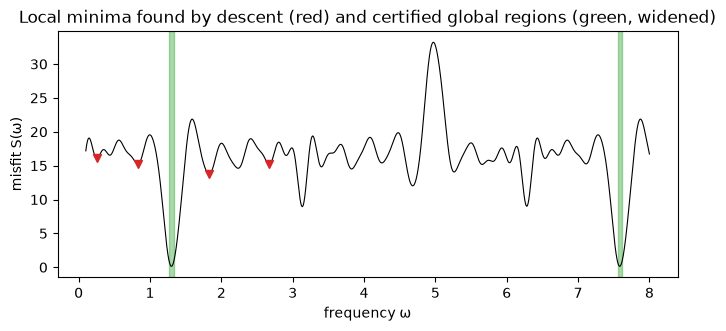

In [8]:
ws = np.linspace(0.1, 8, 3000)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(ws, [misfit_float(w) for w in ws], color="black", linewidth=0.8)
final = minimize(S_combined, domain, tolerance="1/1000", max_splits=3000)
for lo, hi in clusters(final.candidates):
    ax.axvspan(float(lo) - 0.03, float(hi) + 0.03, color="tab:green", alpha=0.4)
for start in [0.2, 0.8, 2.0, 2.6]:
    w = gradient_descent(start)
    ax.plot(w, misfit_float(w), "v", color="tab:red")
ax.set(xlabel="frequency ω", ylabel="misfit S(ω)",
       title="Local minima found by descent (red) and certified global regions (green, widened)")
plt.close(fig)
display(fig)

## 6 · What the certificate covers

- The minimum value is enclosed with a gap of 10⁻³, and **every** global minimizer in the domain lies in the reported regions.
- The claim is about the given decimal data and the model sin(ωt). It says nothing about the noise, about whether the model is right, or about frequencies outside the domain.
- The curve in the figure is sampled in floats and is for illustration only.

## Exercises

1. **Measurement uncertainty.** Suppose each measurement is only known to ±0.005. Replace each y by an interval and minimize the misfit enclosure. How much do the candidate regions grow? (The result now encloses the minimizers for *every* data set consistent with the measurements.)
2. **Irregular sampling.** Change the times to t = 0, 1.1, 2.3, … (exact decimals). Does the second global minimizer disappear? Explain using the identity in Section 5.
3. **Two parameters.** Fit y ≈ A sin(ωt) with unknown amplitude A. `minimize` is one-dimensional; write a 2D branch and bound that splits boxes in their widest direction. (For a challenge, try SIAM 100-digit Problem 4, a rugged 2D function.)
4. **Budget.** Run the natural and combined searches with `max_splits=50`. Report what is still certified when the budget runs out.